Projeto 01 - Análise Exploratória de Dados Olist
Objetivo
Analisar os dados de pedidos do marketplace Olist para entender padrões de vendas, qualidade dos dados e oportunidades de negócio.

In [126]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [127]:
os.listdir("../data")

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

Carregamento dos dados
Nesta etapa carregamos a base de pedidos do dataset Olist para entender a estrutura das informações.

In [128]:

orders = pd.read_csv("../data/olist_orders_dataset.csv")

Primeiras Linhas

In [129]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [130]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [131]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

## Análise de Valores Nulos

A base apresenta dados faltantes principalmente relacionados ao fluxo de entrega.

Os maiores volumes de valores nulos estão nas colunas:

- order_delivered_customer_date
- order_delivered_carrier_date

Isso pode indicar pedidos cancelados, pedidos em andamento ou registros de entrega não concluídos.

As colunas fundamentais para identificação dos pedidos e clientes não apresentam valores ausentes.

--------------------------------------------------------------------------

Esse é um dos gráficos mais importantes do dataset Olist.

Ele vai responder:

Quantos pedidos foram entregues?
Quantos foram cancelados?
Quantos estão em transporte?
Quantos estão processando?

In [132]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

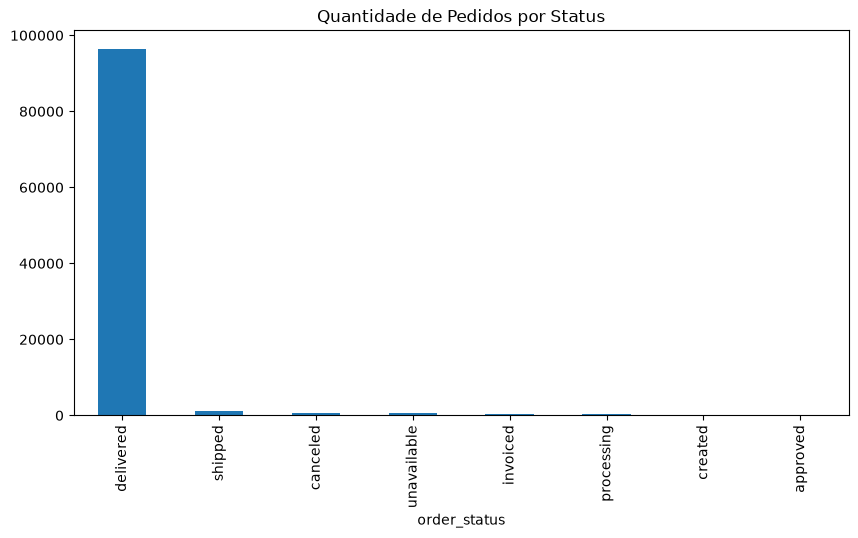

In [133]:
orders["order_status"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Quantidade de Pedidos por Status")


plt.savefig(
    "../images/01_Quantidade_Pedidos_Status.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Análise dos Tempos de Entrega

Nesta etapa vamos calcular o tempo entre a compra e a entrega do pedido, permitindo entender a eficiência logística da operação.

In [134]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [135]:
orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days


In [136]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_time_days"
    ]
].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


In [137]:
orders["delivery_time_days"].describe()

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time_days, dtype: float64

Esse gráfico já começa a responder:

Qual o prazo típico de entrega?
Existem entregas muito demoradas?
Existem outliers?

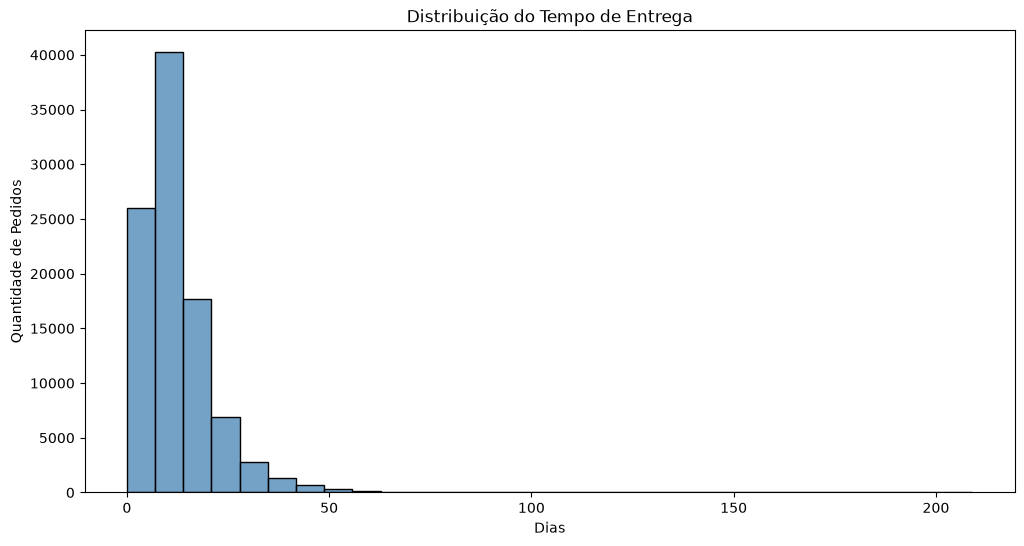

In [138]:
plt.figure(figsize=(12,6))

sns.histplot(
    orders["delivery_time_days"],
    bins=30,
    color="steelblue"
)

plt.title("Distribuição do Tempo de Entrega")
plt.xlabel("Dias")
plt.ylabel("Quantidade de Pedidos")



plt.savefig(
    "../images/02_distribuicao_Tempo_Entrega.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Insight Inicial

A distribuição dos tempos de entrega permite identificar o comportamento padrão da operação logística.

Pedidos com prazo muito superior à média podem indicar gargalos operacionais, problemas de transporte ou restrições geográficas.

In [139]:
media_entrega = int(orders["delivery_time_days"].mean())
mediana_entrega = int(orders["delivery_time_days"].median())
maior_entrega = int(orders["delivery_time_days"].max())
menor_entrega = int(orders["delivery_time_days"].min())

print(f"📦 Tempo médio de entrega: {media_entrega} dias")
print(f"📊 Mediana do tempo de entrega: {mediana_entrega} dias")
print(f"🚚 Maior tempo de entrega: {maior_entrega} dias")

if menor_entrega == 0:
    print("⚡ Menor prazo de entrega: no mesmo dia da compra")
else:
    print(f"⚡ Menor prazo de entrega: {menor_entrega} dias")

📦 Tempo médio de entrega: 12 dias
📊 Mediana do tempo de entrega: 10 dias
🚚 Maior tempo de entrega: 209 dias
⚡ Menor prazo de entrega: no mesmo dia da compra


In [140]:
bins = [0, 3, 7, 14, 30, 60, 365]

labels = [
    "0-3 dias",
    "4-7 dias",
    "8-14 dias",
    "15-30 dias",
    "31-60 dias",
    "60+ dias"
]

orders["delivery_group"] = pd.cut(
    orders["delivery_time_days"],
    bins=bins,
    labels=labels
)

In [141]:
orders["delivery_group"].value_counts().sort_index()

delivery_group
0-3 dias       8589
4-7 dias      25096
8-14 dias     36398
15-30 dias    22262
31-60 dias     3830
60+ dias        288
Name: count, dtype: int64

## Primeira Abordagem: Distribuição do Tempo de Entrega

Inicialmente foi utilizado um histograma para visualizar a distribuição do tempo de entrega dos pedidos.

Embora a visualização represente corretamente os dados, a interpretação não é imediata para usuários de negócio. A presença de valores extremos e a concentração de pedidos em determinadas faixas dificultam a leitura e a extração de insights relevantes.

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_11976\1806356077.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


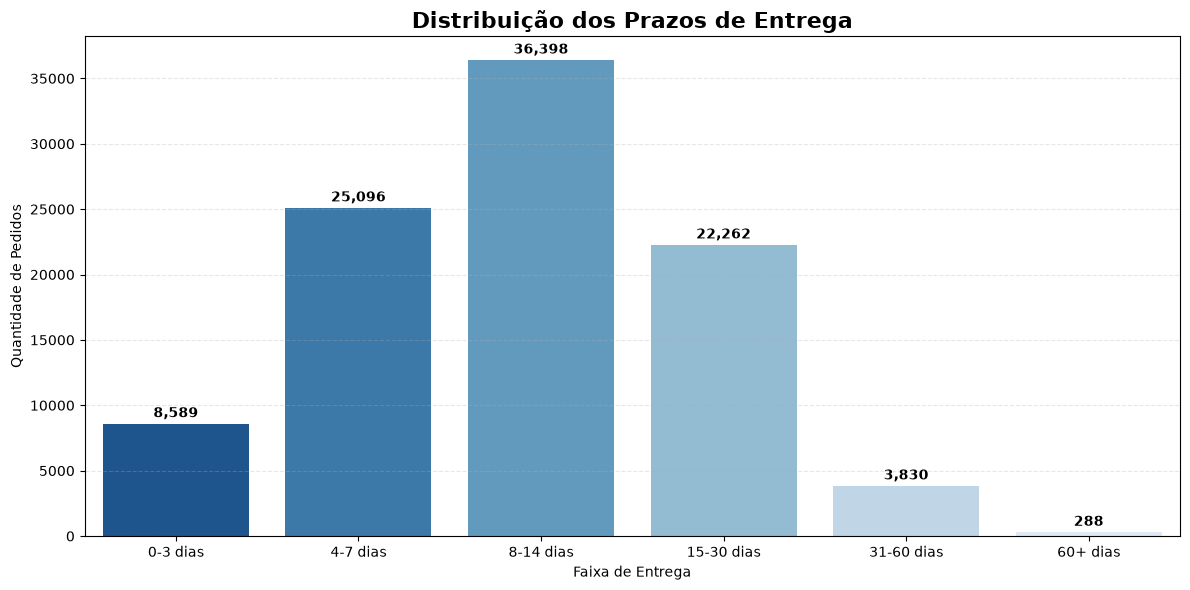

In [142]:
delivery_counts = (
    orders["delivery_group"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    palette="Blues_r"
)

plt.title(
    "Distribuição dos Prazos de Entrega",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Faixa de Entrega")
plt.ylabel("Quantidade de Pedidos")

for i, v in enumerate(delivery_counts.values):
    ax.text(
        i,
        v + 500,
        f"{v:,.0f}",
        ha="center",
        fontweight="bold"
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()



plt.savefig(
    "../images/03_distribuicao_Prazos_Entrega.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Refinamento da Visualização

Após analisar o histograma, foi identificado que a visualização não comunicava de forma clara o comportamento predominante das entregas.

Para tornar a análise mais intuitiva, os pedidos foram agrupados em faixas de prazo de entrega. Essa abordagem reduz a complexidade visual e facilita a identificação dos períodos com maior concentração de entregas.

Além disso, a nova visualização aproxima a análise da linguagem utilizada por áreas de negócio e operações logísticas, permitindo uma interpretação mais rápida dos resultados.

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_11976\2207085768.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


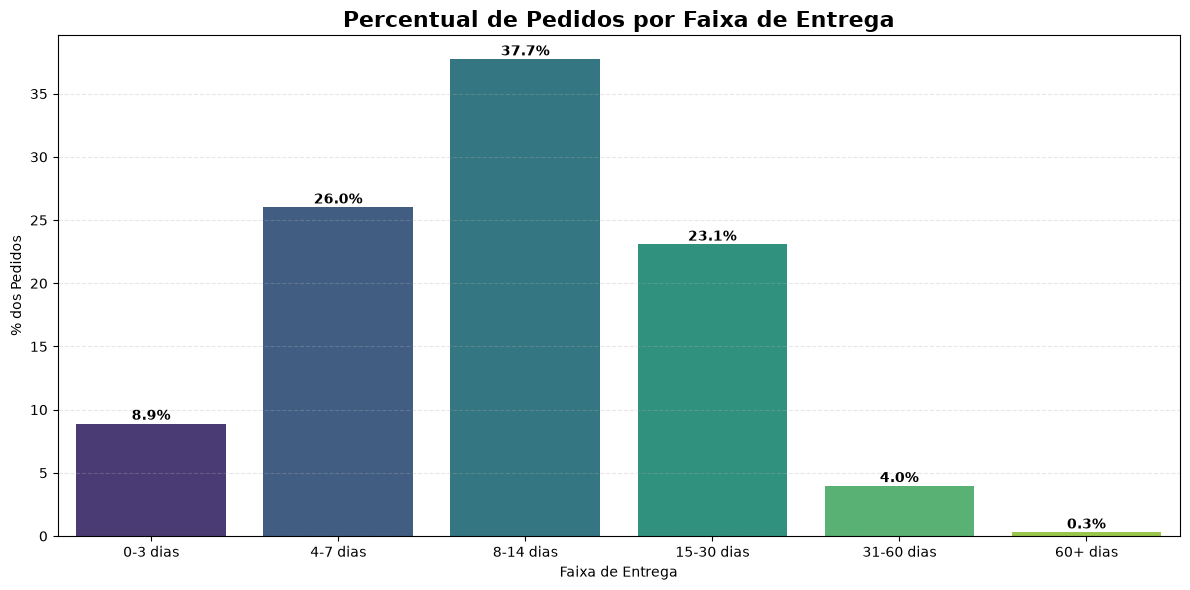

In [149]:
plt.figure(figsize=(12,6))
delivery_pct = (
    orders["delivery_group"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
)

delivery_pct

ax = sns.barplot(
    x=delivery_pct.index,
    y=delivery_pct.values,
    palette="viridis"
)

for i, valor in enumerate(delivery_pct.values):
    ax.text(
        i,
        valor + 0.3,
        f"{valor:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Percentual de Pedidos por Faixa de Entrega",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Faixa de Entrega")
plt.ylabel("% dos Pedidos")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "../images/04_Percentual_Prazo_Entrega.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Principais Insights

A visualização por faixas permite observar com maior clareza o comportamento da operação logística.

Os resultados indicam que a maior parte dos pedidos foi entregue entre 8 e 14 dias, seguida pelas entregas realizadas entre 4 e 7 dias.

Também é possível identificar que entregas acima de 60 dias representam uma parcela muito pequena da operação, caracterizando situações excepcionais.

Comparada ao histograma inicial, a categorização por faixas tornou a análise mais acessível e mais adequada para comunicação executiva.

In [144]:
bins = [0, 2, 5, 10, 15, 30, 365]

labels = [
    "Até 2 dias",
    "3-5 dias",
    "6-10 dias",
    "11-15 dias",
    "16-30 dias",
    "Mais de 30 dias"
]

In [145]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

In [146]:
orders["delivery_delay_days"]

0        -8.0
1        -6.0
2       -18.0
3       -13.0
4       -10.0
         ... 
99436   -11.0
99437    -2.0
99438    -6.0
99439   -21.0
99440   -18.0
Name: delivery_delay_days, Length: 99441, dtype: float64

In [147]:

atrasados = (orders["delivery_delay_days"] > 0).sum()

no_prazo = (orders["delivery_delay_days"] <= 0).sum()

taxa_atraso = (
    (orders["delivery_delay_days"] > 0).mean() * 100
)

print(f"🚨 Pedidos atrasados: {atrasados}")
print(f"✅ Pedidos no prazo: {no_prazo}")
print(f"📦 Taxa de pedidos atrasados: {taxa_atraso:.1f}%")

🚨 Pedidos atrasados: 6535
✅ Pedidos no prazo: 89941
📦 Taxa de pedidos atrasados: 6.6%


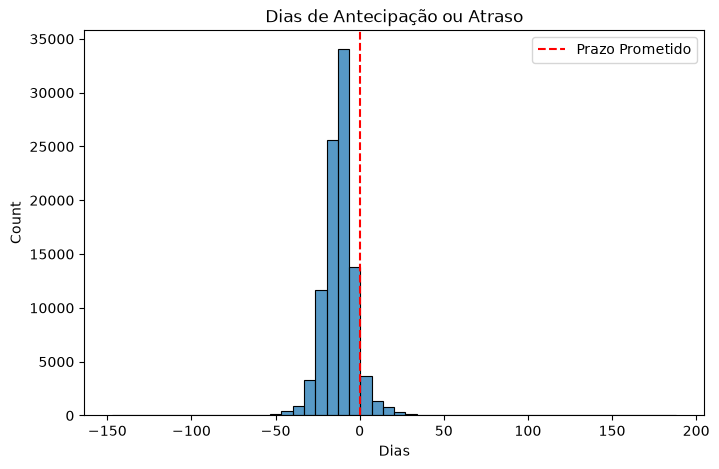

In [148]:
plt.figure(figsize=(8,5))

sns.histplot(
    orders["delivery_delay_days"],
    bins=50
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Prazo Prometido"
)

plt.legend()
plt.title("Dias de Antecipação ou Atraso")
plt.xlabel("Dias")


plt.savefig(
    "../images/05_Dias_Antecipacao_Atraso.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Insight

A análise dos prazos mostrou que parte dos pedidos foi entregue após a data prometida ao cliente.

Esta métrica é importante para avaliar a eficiência logística e o impacto na experiência do consumidor.

Como os Pedidos Evoluiram ao longo do Tempo ?

In [150]:
orders["order_purchase_year_month"] = (
    orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

In [151]:
monthly_orders = (
    orders.groupby("order_purchase_year_month")
    .size()
)

monthly_orders.head()

order_purchase_year_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
Freq: M, dtype: int64

In [152]:
monthly_orders.index = (
    monthly_orders.index
    .to_timestamp()
)

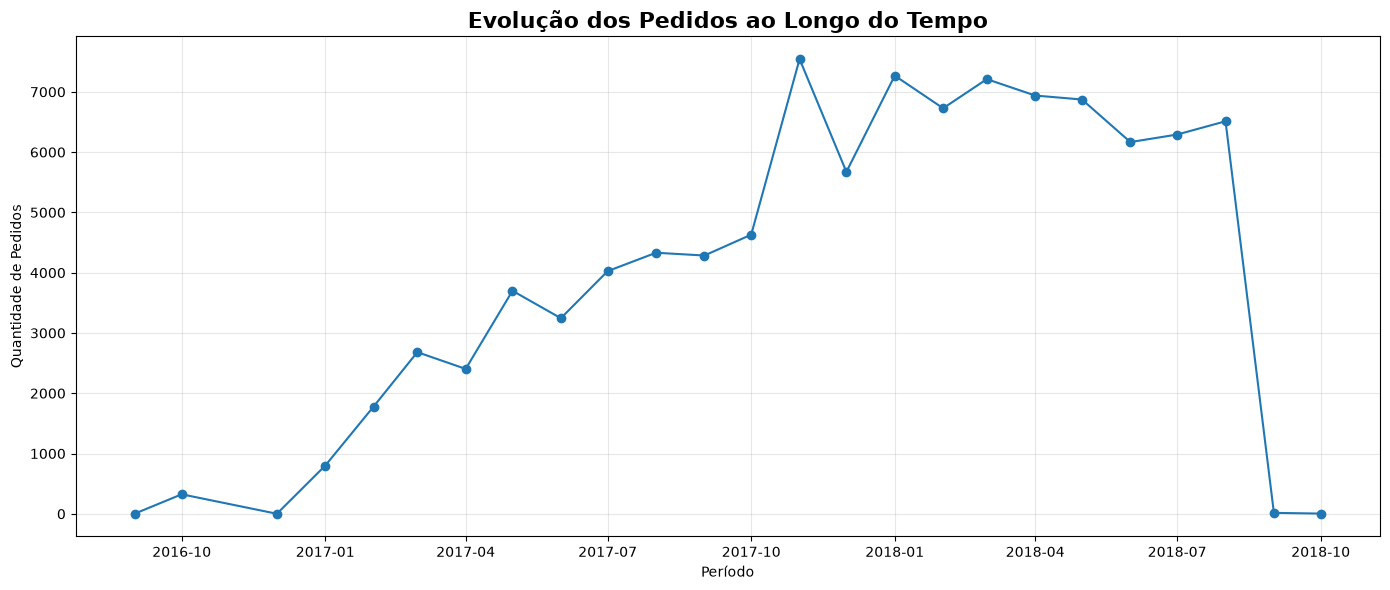

In [153]:
plt.figure(figsize=(14,6))

plt.plot(
    monthly_orders.index,
    monthly_orders.values,
    marker="o"
)

plt.title(
    "Evolução dos Pedidos ao Longo do Tempo",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Período")
plt.ylabel("Quantidade de Pedidos")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../images/06_evolucao_pedidos_tempo.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Refinamento da Visualização Temporal

A visualização inicial apresentava todos os pedidos do período analisado em uma única série temporal.

Apesar de correta do ponto de vista técnico, essa abordagem dificultava a leitura dos dados, pois os picos de diferentes anos ficavam concentrados no mesmo gráfico.

Para tornar a análise mais intuitiva, optou-se por segmentar os dados por ano e avaliar a distribuição mensal dos pedidos individualmente.

Essa mudança permitiu uma leitura mais clara dos padrões de demanda e facilitou a identificação de possíveis comportamentos sazonais.

In [154]:
orders["ano"] = (
    orders["order_purchase_timestamp"]
    .dt.year
)

In [155]:
orders["ano"].value_counts().sort_index()

ano
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

In [156]:
orders_2016 = orders[
    orders["ano"] == 2016
].copy()

print(f"Quantidade de pedidos em 2016: {len(orders_2016):,}")

Quantidade de pedidos em 2016: 329


In [157]:
orders_2016["mes"] = (
    orders_2016["order_purchase_timestamp"]
    .dt.month
)

In [158]:
pedidos_mes_2016 = (
    orders_2016
    .groupby("mes")
    .size()
)

pedidos_mes_2016

mes
9       4
10    324
12      1
dtype: int64

In [161]:
orders_2017 = orders[
    orders["ano"] == 2017
].copy()


In [162]:
orders_2017["mes"] = (
    orders_2017["order_purchase_timestamp"]
    .dt.month
)

In [163]:
pedidos_mes_2017 = (
    orders_2017
    .groupby("mes")
    .size()
)

pedidos_mes_2017

mes
1      800
2     1780
3     2682
4     2404
5     3700
6     3245
7     4026
8     4331
9     4285
10    4631
11    7544
12    5673
dtype: int64

## Início da Operação - 2016

Os dados de 2016 apresentam registros concentrados em poucos meses e com baixo volume de pedidos quando comparados aos anos seguintes.

Devido à quantidade limitada de observações e à forte concentração dos pedidos em um único período, optou-se por não utilizar visualizações gráficas para este ano.

Essa decisão evita interpretações equivocadas e direciona a análise para períodos com maior representatividade estatística.

## Evolução dos Pedidos em 2017

Após avaliar os registros de 2016, observou-se que a quantidade limitada de meses disponíveis não permitia uma análise temporal consistente.

Dessa forma, a análise passa a considerar o ano de 2017, que apresenta uma quantidade maior de registros e permite identificar tendências, crescimento da operação e possíveis padrões ao longo dos meses.

## Análise dos registro de 2017 

O ano de 2017 apresentou registros durante todos os meses, permitindo uma análise temporal mais completa da operação.

Diferentemente de 2016, que possuía uma quantidade reduzida de observações, 2017 possibilita identificar tendências de crescimento e eventuais períodos de maior concentração de pedidos ao longo do ano.


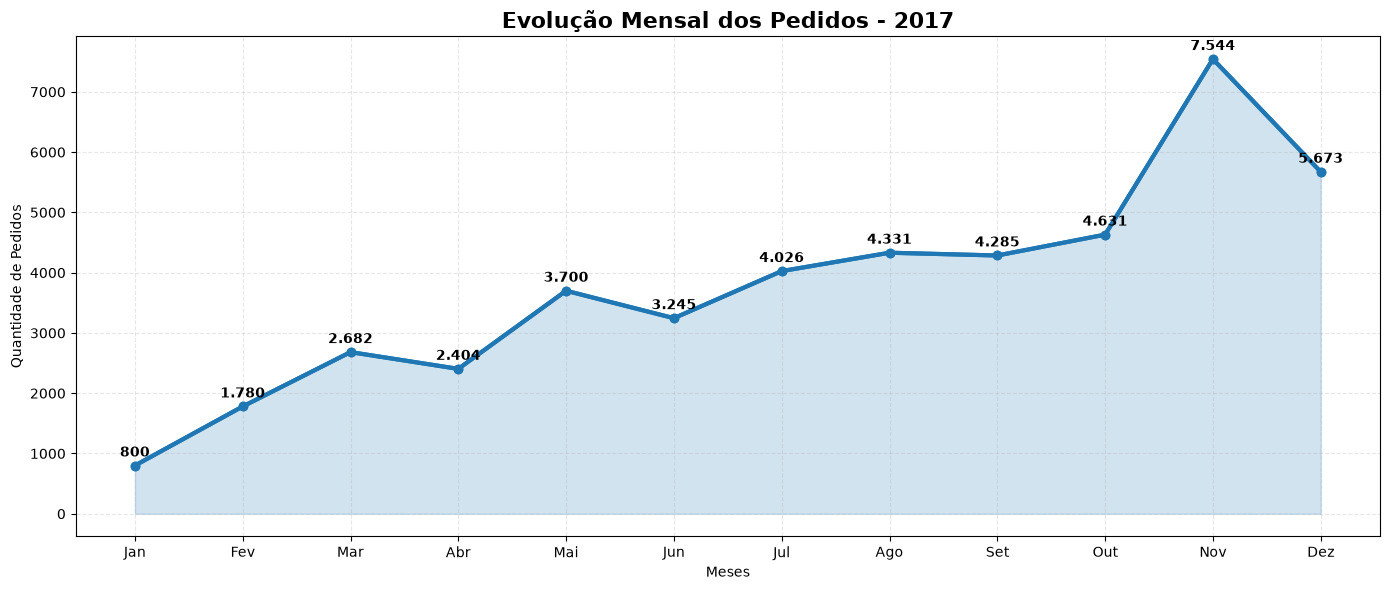

<Figure size 1400x600 with 0 Axes>

In [168]:
plt.figure(figsize=(14,6))

plt.plot(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values,
    marker="o",
    linewidth=3,
    color="#1f77b4"
)

plt.fill_between(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values,
    alpha=0.2,
    color="#1f77b4"
)

plt.plot(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values,
    marker="o",
    linewidth=3,
    color="#1f77b4"
)

for x, y in zip(
    pedidos_mes_2017.index,
    pedidos_mes_2017.values
):
    plt.text(
        x,
        y + 150,
        f"{y:,}".replace(",", "."),
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Evolução Mensal dos Pedidos - 2017",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Meses")
plt.ylabel("Quantidade de Pedidos")

plt.grid(
    linestyle="--",
    alpha=0.3
)

meses = [
    "Jan", "Fev", "Mar", "Abr",
    "Mai", "Jun", "Jul", "Ago",
    "Set", "Out", "Nov", "Dez"
]

plt.xticks(
    ticks=range(1,13),
    labels=meses
)
plt.tight_layout()

plt.savefig(
    "../images/07_evolucao_pedidos_2017.png",
    bbox_inches="tight",
    dpi=300
)
plt.figure(figsize=(14,6))



plt.show()